<a href="https://colab.research.google.com/github/dhanwariagarvit21/unified_theory_of_orderflow_vol_implementation/blob/main/bivariate_hawkes_proces.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import numpy as np
import pandas as pd
import torch
import math
import zipfile
import torch.nn.functional as F
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import expon,uniform
from scipy.optimize import minimize
from torch._higher_order_ops.associative_scan import associative_scan

In [24]:
def clean_mem():
    gc.collect()
    torch.cuda.empty_cache()

In [25]:
columns = [
    "trade_id",
    "price",
    "qty",
    "quote_qty",
    "timestamp",
    "is_buyer_maker",
    "is_best_match"
]
df = pd.read_csv('/content/BTCEUR-trades-2026-10.csv',names=columns)

In [26]:
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="us",
    utc=True
)
df["direction"] = df["is_buyer_maker"].map({
    True: -1,
    False: 1
})
df["signed_qty"] = (
    df["direction"] * df["qty"]
)

df["signed_quote_qty"] = (
    df["direction"] * df["quote_qty"]
)
df["buy_event"] = (
    df["direction"] == 1
).astype(int)

df["sell_event"] = (
    df["direction"] == -1
).astype(int)
df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)

df["interarrival_ms"] = (
    df["timestamp"].diff() / 1000
)
df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)
df["interarrival_ms"] = (
    df["timestamp"].diff() / 1000
)

In [27]:
print("Before cleaning:", len(df))

df = df.dropna(
    subset=[
        "timestamp",
        "price",
        "qty",
        "is_buyer_maker"
    ]
).copy()

df = df.sort_values(
    ["timestamp", "trade_id"]
).reset_index(drop=True)

print("After cleaning:", len(df))
print("Remaining missing values:")
print(df.isna().sum())

Before cleaning: 685061
After cleaning: 685061
Remaining missing values:
trade_id            0
price               0
qty                 0
quote_qty           0
timestamp           0
is_buyer_maker      0
is_best_match       0
datetime            0
direction           0
signed_qty          0
signed_quote_qty    0
buy_event           0
sell_event          0
interarrival_ms     1
dtype: int64


In [28]:
buy_times = np.sort(
    df.loc[df["direction"] == 1, "timestamp"].unique()
)

sell_times = np.sort(
    df.loc[df["direction"] == -1, "timestamp"].unique()
)

In [29]:
print("Buy events:", len(buy_times))
print("Sell events:", len(sell_times))

print("Buy sorted:", np.all(np.diff(buy_times) > 0))
print("Sell sorted:", np.all(np.diff(sell_times) > 0))

print("Buy range:", buy_times[0], buy_times[-1])
print("Sell range:", sell_times[0], sell_times[-1])

Buy events: 255423
Sell events: 280726
Buy sorted: True
Sell sorted: True
Buy range: 1790812801147152 1793491194469074
Sell range: 1790812805367798 1793491198603196


In [30]:
t0 = min(buy_times[0], sell_times[0])
buy_t = (buy_times - t0) / 1_000_000
sell_t = (sell_times - t0) / 1_000_000

In [31]:

def excitation_logcumsumexp(counts, times, beta, init_state):
    n = times.shape[0]
    mask = counts > 0
    m_long = mask.to(torch.long)
    idx = torch.cumsum(m_long, 0) - m_long
    exc = torch.zeros(n, dtype=times.dtype, device=times.device)
    if bool(mask.any()):
        t_act, c_act = times[mask], counts[mask]
        L = torch.logcumsumexp(beta * t_act + torch.log(c_act), dim=0)
        l_prev = L[idx.clamp(min=1) - 1]
        arg = l_prev - beta * times
        arg = torch.where(idx > 0, arg, torch.full_like(arg, -1e30))
        exc = torch.exp(arg)
    return exc + init_state * torch.exp(-beta * (times - times[0]))


def bivariate_hawkes_nll_gpu(buy_counts, sell_counts, params, times, T,
                             init_excitation_buy=0.0, init_excitation_sell=0.0):
    mu1, mu2, alpha_1, alpha_2, alpha_3, alpha_4, beta = params
    device, dtype = times.device, times.dtype

    def as_state(x):
        if torch.is_tensor(x):
            return x.to(device=device, dtype=dtype).reshape(())
        return torch.tensor(x, dtype=dtype, device=device)

    init_buy, init_sell = as_state(init_excitation_buy), as_state(init_excitation_sell)
    exc_buy = excitation_logcumsumexp(buy_counts, times, beta, init_buy)
    exc_sell = excitation_logcumsumexp(sell_counts, times, beta, init_sell)
    intensity_buy = mu1 + alpha_1 * exc_buy + alpha_2 * exc_sell
    intensity_sell = mu2 + alpha_3 * exc_buy + alpha_4 * exc_sell

    event_ll = torch.sum(buy_counts * torch.log(intensity_buy) + sell_counts * torch.log(intensity_sell))

    decay_integral = 1.0 - torch.exp(-beta * (T - times))
    buy_integral = torch.sum(buy_counts * decay_integral)
    sell_integral = torch.sum(sell_counts * decay_integral)
    init_integral = (1.0 - torch.exp(-beta * T)) / beta
    compensator = ((mu1 + mu2) * T
                   + (alpha_1 + alpha_3) / beta * buy_integral
                   + (alpha_2 + alpha_4) / beta * sell_integral
                   + (alpha_1 + alpha_3) * init_buy * init_integral
                   + (alpha_2 + alpha_4) * init_sell * init_integral)
    final_decay = torch.exp(-beta * (T - times[-1]))
    end_buy = (exc_buy[-1] + buy_counts[-1]) * final_decay
    end_sell = (exc_sell[-1] + sell_counts[-1]) * final_decay

    return -(event_ll - compensator), end_buy, end_sell


def check_excitation(buy_counts, sell_counts, times, beta=50.0, n_check=(10, 200, 2000), init=0.0):
    z = torch.tensor(float(init), dtype=times.dtype, device=times.device)
    b = torch.tensor(float(beta), dtype=times.dtype, device=times.device)
    local = times - times[0]
    eb = excitation_logcumsumexp(buy_counts, local, b, z)
    es = excitation_logcumsumexp(sell_counts, local, b, z)
    t, bc, sc = local.cpu().numpy(), buy_counts.cpu().numpy(), sell_counts.cpu().numpy()
    for n in n_check:
        d = np.exp(-beta * (t[n] - t[:n]))
        bb = (bc[:n] * d).sum() + init * np.exp(-beta * (t[n] - t[0]))
        ss = (sc[:n] * d).sum() + init * np.exp(-beta * (t[n] - t[0]))
        print(f"n={n}: fast=({eb[n].item():.8f}, {es[n].item():.8f})  brute=({bb:.8f}, {ss:.8f})")
        assert abs(eb[n].item() - bb) < 1e-7 and abs(es[n].item() - ss) < 1e-7, "excitation mismatch"
    print("excitation check passed")


def check_gradient(buy_counts, sell_counts, times, T):
    z = torch.tensor([-2.3, -2.7, 1.0, -3.0, 1.5, -3.0, 3.9], dtype=times.dtype, device=times.device, requires_grad=True)
    mu1, mu2 = torch.exp(z[0]), torch.exp(z[1])
    beta = torch.exp(z[6])
    a = torch.exp(z[2:6])
    nll, _, _ = bivariate_hawkes_nll_gpu(buy_counts, sell_counts, (mu1, mu2, a[0], a[1], a[2], a[3], beta),
                                         times - times[0], float((times[-1] - times[0]).item()))
    nll.backward()
    print("nll", nll.item(), "grad", z.grad.detach().cpu().numpy())
    assert torch.isfinite(z.grad).all(), "non-finite gradient"
    print("gradient check passed")

In [32]:
all_times = np.concatenate([buy_t, sell_t])
all_directions = np.concatenate([
    np.ones(len(buy_t), dtype=np.int8),
    -np.ones(len(sell_t), dtype=np.int8)
])
order = np.argsort(all_times, kind="stable")

all_times = all_times[order]
all_directions = all_directions[order]
unique_times, inverse = np.unique(
    all_times,
    return_inverse=True
)

buy_counts = np.bincount(
    inverse,
    weights=(all_directions == 1).astype(float)
)

sell_counts = np.bincount(
    inverse,
    weights=(all_directions == -1).astype(float)
)

print("Unique event timestamps:", len(unique_times))
print("Buy events:", buy_counts.sum())
print("Sell events:", sell_counts.sum())
print("Simultaneous timestamps:",
      np.sum((buy_counts > 0) & (sell_counts > 0)))

Unique event timestamps: 536074
Buy events: 255423.0
Sell events: 280726.0
Simultaneous timestamps: 75


In [33]:
device = torch.device("cuda")
times_gpu = torch.as_tensor(
    unique_times,
    dtype=torch.float64,
    device=device
)

buy_counts_gpu = torch.as_tensor(
    buy_counts,
    dtype=torch.float64,
    device=device
)
sell_counts_gpu = torch.as_tensor(
    sell_counts,
    dtype=torch.float64,
    device=device
)
T = unique_times[-1]
T_gpu = float(T)

print("Unique timestamps:", len(unique_times))
print("Buy events:", buy_counts_gpu.sum().item())
print("Sell events:", sell_counts_gpu.sum().item())


Unique timestamps: 536074
Buy events: 255423.0
Sell events: 280726.0


In [34]:
clean_mem()

In [35]:

def fit_bivariate_hawkes_nll_gpu_batched(
    buy_counts,
    sell_counts,
    times,
    T,
    n_starts=12,
    batch_size=10000
):
    device = times.device
    if batch_size < 1:
        raise ValueError("batch_size must be positive.")

    if n_starts < 1:
        raise ValueError("n_starts must be positive.")

    if len(times) == 0:
        raise ValueError("No observations supplied.")

    if len(buy_counts) != len(times) or len(sell_counts) != len(times):
        raise ValueError("Input arrays must have equal lengths.")

    if not torch.all(torch.isfinite(times)):
        raise ValueError("Timestamps contain non-finite values.")

    if not torch.all(times[1:] > times[:-1]):
        raise ValueError(
            "Timestamps must be strictly increasing. "
            "Aggregate simultaneous events first."
        )

    if T <= 0 or T < times[-1].item():
        raise ValueError(
            "T must be positive and at least as large as the final timestamp."
        )
    def transform_parameters(z):

        mu_buy = torch.exp(z[0])
        mu_sell = torch.exp(z[1])

        eta_buy = torch.sigmoid(z[2])
        split_buy = torch.sigmoid(z[3])

        eta_sell = torch.sigmoid(z[4])
        split_sell = torch.sigmoid(z[5])

        beta = torch.exp(z[6])

        alpha_bb = beta * eta_buy * split_buy
        alpha_bs = beta * eta_buy * (1 - split_buy)

        alpha_sb = beta * eta_sell * split_sell
        alpha_ss = beta * eta_sell * (1 - split_sell)

        return (
            mu_buy,
            mu_sell,
            alpha_bb,
            alpha_bs,
            alpha_sb,
            alpha_ss,
            beta
        )
    def objective_and_gradient(z_np):

        z = torch.tensor(
            z_np,
            dtype=torch.float64,
            device=device,
            requires_grad=True
        )

        params = transform_parameters(z)

        n_samples = len(times)
        carry_buy = torch.zeros(
            (),
            dtype=torch.float64,
            device=device
        )

        carry_sell = torch.zeros(
            (),
            dtype=torch.float64,
            device=device
        )
        total_loss = (
            (params[0] + params[1]) * times[0]
        )
        for i in range(0, n_samples, batch_size):

            end_idx = min(i + batch_size, n_samples)

            chunk_times = times[i:end_idx]
            chunk_buy = buy_counts[i:end_idx]
            chunk_sell = sell_counts[i:end_idx]

            chunk_T = chunk_times[-1] - chunk_times[0]

            local_times = (
                chunk_times - chunk_times[0]
            )

            chunk_loss, carry_buy, carry_sell = (
                bivariate_hawkes_nll_gpu(
                    chunk_buy,
                    chunk_sell,
                    params,
                    local_times,
                    chunk_T,
                    init_excitation_buy=carry_buy,
                    init_excitation_sell=carry_sell
                )
            )

            total_loss = total_loss + chunk_loss
            if end_idx < n_samples:

                gap = (
                    times[end_idx] - chunk_times[-1]
                )

                gap_decay_integral = (
                    1.0 - torch.exp(-params[6] * gap)
                ) / params[6]

                gap_integral = (
                    (params[0] + params[1]) * gap
                    + (
                        (params[2] + params[4]) * carry_buy
                        + (params[3] + params[5]) * carry_sell
                    ) * gap_decay_integral
                )

                total_loss = (
                    total_loss + gap_integral
                )


                decay = torch.exp(
                    -params[6] * gap
                )

                carry_buy = carry_buy * decay
                carry_sell = carry_sell * decay
        tail = T - times[-1]

        tail_decay_integral = (
            1.0 - torch.exp(-params[6] * tail)
        ) / params[6]

        terminal_integral = (
            (params[2] + params[4]) * carry_buy
            + (params[3] + params[5]) * carry_sell
        ) * tail_decay_integral

        total_loss = (
            total_loss
            + (params[0] + params[1]) * tail
            + terminal_integral
        )
        if not torch.isfinite(total_loss):
            return (
                1e100,
                np.zeros(7, dtype=np.float64)
            )

        total_loss.backward()

        gradient = z.grad.detach().cpu().numpy()

        return (
            total_loss.item(),
            gradient.astype(np.float64)
        )
    n_buy = buy_counts.sum().item()
    n_sell = sell_counts.sum().item()

    mu_buy_initial = max(
        n_buy / T * 0.5,
        1e-8
    )

    mu_sell_initial = max(
        n_sell / T * 0.5,
        1e-8
    )

    beta_values = [
        1.0, 5.0, 10.0, 50.0, 100.0, 500.0
    ]

    eta_values = [
        0.2, 0.4, 0.6, 0.8
    ]

    split_values = [
        0.1, 0.3, 0.5, 0.7, 0.9
    ]

    starts = []
    for i in range(n_starts):

        beta0 = beta_values[i % len(beta_values)]

        eta_buy0 = eta_values[i % len(eta_values)]

        eta_sell0 = eta_values[
            (i // len(beta_values)) % len(eta_values)
        ]

        split_buy0 = split_values[
            i % len(split_values)
        ]

        split_sell0 = split_values[
            (i // len(split_values)) % len(split_values)
        ]

        starts.append(
            np.array([
                np.log(mu_buy_initial),
                np.log(mu_sell_initial),

                np.log(eta_buy0 / (1 - eta_buy0)),
                np.log(split_buy0 / (1 - split_buy0)),

                np.log(eta_sell0 / (1 - eta_sell0)),
                np.log(split_sell0 / (1 - split_sell0)),

                np.log(beta0)
            ], dtype=np.float64)
        )
    best_result = None
    all_results = []

    bounds = [
        (-20, 2),
        (-20, 2),
        (-10, 10),
        (-10, 10),
        (-10, 10),
        (-10, 10),
        (np.log(1e-3), np.log(1e4))
    ]

    for start_number, z0 in enumerate(starts, 1):

        result = minimize(
            objective_and_gradient,
            z0,
            method="L-BFGS-B",
            jac=True,
            bounds=bounds,
            options={
                "maxiter": 100,
                "ftol": 1e-8,
                "gtol": 1e-5,
                "maxls": 20
            }
        )

        all_results.append(result)

        print(
            f"Start {start_number}/{n_starts}: "
            f"NLL = {result.fun:.6f}, "
            f"Success = {result.success}, "
            f"Iterations = {result.nit}, "
            f"Gradient norm = {np.linalg.norm(result.jac):.6e}"
        )

        if (
            np.isfinite(result.fun)
            and np.all(np.isfinite(result.jac))
            and (
                best_result is None
                or result.fun < best_result.fun
            )
        ):
            best_result = result

    if best_result is None:
        raise RuntimeError(
            "All optimization runs failed."
        )
    z_best = torch.tensor(
        best_result.x,
        dtype=torch.float64,
        device=device
    )

    params = transform_parameters(z_best)

    (
        mu_buy,
        mu_sell,
        alpha_bb,
        alpha_bs,
        alpha_sb,
        alpha_ss,
        beta
    ) = [p.item() for p in params]
    branching_matrix = np.array([
        [
            alpha_bb / beta,
            alpha_bs / beta
        ],
        [
            alpha_sb / beta,
            alpha_ss / beta
        ]
    ])

    spectral_radius = max(
        abs(np.linalg.eigvals(branching_matrix))
    )
    return {
        "mu_buy": mu_buy,
        "mu_sell": mu_sell,

        "alpha_bb": alpha_bb,
        "alpha_bs": alpha_bs,
        "alpha_sb": alpha_sb,
        "alpha_ss": alpha_ss,

        "beta": beta,

        "branching_matrix": branching_matrix,
        "spectral_radius": spectral_radius,

        "log_likelihood": -best_result.fun,
        "negative_log_likelihood": best_result.fun,

        "success": best_result.success,
        "message": best_result.message,

        "gradient_norm": np.linalg.norm(best_result.jac),
        "iterations": best_result.nit,

        "all_results": all_results
    }


In [36]:
bivariate_model = fit_bivariate_hawkes_nll_gpu_batched(
    buy_counts_gpu,
    sell_counts_gpu,
    times_gpu,
    T_gpu,
    n_starts=6,
    batch_size=10000
)
display(bivariate_model)

Start 1/6: NLL = 105303.244221, Success = True, Iterations = 25, Gradient norm = 2.872297e+01
Start 2/6: NLL = 105303.244470, Success = True, Iterations = 21, Gradient norm = 3.308259e+00
Start 3/6: NLL = 105303.243788, Success = True, Iterations = 22, Gradient norm = 1.050199e+01
Start 4/6: NLL = 105303.243404, Success = True, Iterations = 20, Gradient norm = 1.373080e+01
Start 5/6: NLL = 105303.248357, Success = True, Iterations = 20, Gradient norm = 3.093536e+01
Start 6/6: NLL = 105303.243876, Success = True, Iterations = 20, Gradient norm = 2.780117e+01


{'mu_buy': 0.04803825422023357,
 'mu_sell': 0.05910572751482274,
 'alpha_bb': 202.64199585535735,
 'alpha_bs': 1.9535627628904253,
 'alpha_sb': 1.704504935338624,
 'alpha_ss': 178.4048185652174,
 'beta': 412.67506720918664,
 'branching_matrix': array([[0.49104492, 0.0047339 ],
        [0.00413038, 0.43231305]]),
 'spectral_radius': np.float64(0.4913759717095066),
 'log_likelihood': -105303.24340403064,
 'negative_log_likelihood': 105303.24340403064,
 'success': True,
 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH',
 'gradient_norm': np.float64(13.73079803444566),
 'iterations': 20,
 'all_results': [  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    success: True
     status: 0
        fun: 105303.24422058494
          x: [-3.036e+00 -2.828e+00 -1.686e-02  4.643e+00 -2.554e-01
              -4.651e+00  6.023e+00]
        nit: 25
        jac: [-4.333e+00  6.544e+00  8.592e-01  4.805e-01  6.560e+00
               1.376e-01  2.682e+01]
       nfev: 32
  

In [37]:
clean_mem()

In [38]:
bivariate_model = fit_bivariate_hawkes_nll_gpu_batched(
    buy_counts_gpu,
    sell_counts_gpu,
    times_gpu,
    T_gpu,
    n_starts=6,
    batch_size=15000
)
display(bivariate_model)

Start 1/6: NLL = 105303.247342, Success = True, Iterations = 26, Gradient norm = 4.062030e+01
Start 2/6: NLL = 105303.243128, Success = True, Iterations = 22, Gradient norm = 1.533623e+01
Start 3/6: NLL = 105303.254343, Success = True, Iterations = 20, Gradient norm = 2.948150e+01
Start 4/6: NLL = 105303.243234, Success = True, Iterations = 21, Gradient norm = 3.700082e+01
Start 5/6: NLL = 105303.243583, Success = True, Iterations = 24, Gradient norm = 9.032694e+00
Start 6/6: NLL = 105303.247707, Success = True, Iterations = 21, Gradient norm = 1.357926e+01


{'mu_buy': 0.048039957862079534,
 'mu_sell': 0.059105020974736466,
 'alpha_bb': 202.653316103808,
 'alpha_bs': 1.9531103347855765,
 'alpha_sb': 1.703578444461536,
 'alpha_ss': 178.4186918202705,
 'beta': 412.68626982846416,
 'branching_matrix': array([[0.49105902, 0.00473268],
        [0.00412802, 0.43233494]]),
 'spectral_radius': np.float64(0.49138984297425015),
 'log_likelihood': -105303.24312819762,
 'negative_log_likelihood': 105303.24312819762,
 'success': True,
 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH',
 'gradient_norm': np.float64(15.336225813202514),
 'iterations': 22,
 'all_results': [  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    success: True
     status: 0
        fun: 105303.24734209658
          x: [-3.036e+00 -2.828e+00 -1.689e-02  4.642e+00 -2.555e-01
              -4.652e+00  6.023e+00]
        nit: 26
        jac: [-1.197e-01 -4.619e-01  6.303e-01  2.916e-02  2.659e+00
              -1.751e-01 -4.053e+01]
       nfev: 42


In [39]:
clean_mem()

In [40]:
bivariate_model = fit_bivariate_hawkes_nll_gpu_batched(
    buy_counts_gpu,
    sell_counts_gpu,
    times_gpu,
    T_gpu,
    n_starts=6,
    batch_size=5000
)
display(bivariate_model)

Start 1/6: NLL = 105303.243356, Success = True, Iterations = 25, Gradient norm = 6.537074e+00
Start 2/6: NLL = 105303.243076, Success = True, Iterations = 20, Gradient norm = 3.304116e+00
Start 3/6: NLL = 105303.243267, Success = True, Iterations = 21, Gradient norm = 5.372709e+00
Start 4/6: NLL = 105303.243090, Success = True, Iterations = 20, Gradient norm = 6.904457e+00
Start 5/6: NLL = 105303.243140, Success = True, Iterations = 20, Gradient norm = 9.292463e+00
Start 6/6: NLL = 105303.244903, Success = True, Iterations = 19, Gradient norm = 7.360210e+00


{'mu_buy': 0.04803977546281964,
 'mu_sell': 0.059105080136054054,
 'alpha_bb': 202.6464196886663,
 'alpha_bs': 1.953207831765238,
 'alpha_sb': 1.703437037877555,
 'alpha_ss': 178.41153968546018,
 'beta': 412.6795405471934,
 'branching_matrix': array([[0.49105032, 0.00473299],
        [0.00412775, 0.43232465]]),
 'spectral_radius': np.float64(0.4913811300835389),
 'log_likelihood': -105303.24307595205,
 'negative_log_likelihood': 105303.24307595205,
 'success': True,
 'message': 'CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH',
 'gradient_norm': np.float64(3.3041158461455042),
 'iterations': 20,
 'all_results': [  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    success: True
     status: 0
        fun: 105303.24335566584
          x: [-3.036e+00 -2.828e+00 -1.696e-02  4.642e+00 -2.555e-01
              -4.652e+00  6.023e+00]
        nit: 25
        jac: [ 2.142e+00 -7.078e-01 -2.227e+00 -2.888e-01  7.108e-01
              -1.847e-01  5.662e+00]
       nfev: 32
  

In [41]:
@torch.no_grad()
def hawkes_nll_segment(buy, sell, times, params, t_start, t_end, init_buy, init_sell, batch_size=10000):
    mu1, mu2, a_bb, a_bs, a_sb, a_ss, beta = params
    dtype, device = times.dtype, times.device
    init_buy = torch.as_tensor(init_buy, dtype=dtype, device=device).reshape(())
    init_sell = torch.as_tensor(init_sell, dtype=dtype, device=device).reshape(())
    def inherited(cb, cs, dur):
        return ((a_bb + a_sb) * cb + (a_bs + a_ss) * cs) * (1.0 - torch.exp(-beta * dur)) / beta
    if times.numel() == 0:
        dur = t_end - t_start
        total = (mu1 + mu2) * dur + inherited(init_buy, init_sell, dur)
        decay = torch.exp(-beta * dur)
        return total, init_buy * decay, init_sell * decay
    g0 = times[0] - t_start
    total = (mu1 + mu2) * g0 + inherited(init_buy, init_sell, g0)
    carry_buy = init_buy * torch.exp(-beta * g0)
    carry_sell = init_sell * torch.exp(-beta * g0)

    n = times.numel()
    for i in range(0, n, batch_size):
        e = min(i + batch_size, n)
        chunk_times = times[i:e]
        local = chunk_times - chunk_times[0]
        chunk_T = chunk_times[-1] - chunk_times[0]
        loss, carry_buy, carry_sell = bivariate_hawkes_nll_gpu(
            buy[i:e], sell[i:e], params, local, chunk_T,
            init_excitation_buy=carry_buy, init_excitation_sell=carry_sell)
        total = total + loss
        if e < n:
            gap = times[e] - chunk_times[-1]
            total = total + (mu1 + mu2) * gap + inherited(carry_buy, carry_sell, gap)
            decay = torch.exp(-beta * gap)
            carry_buy, carry_sell = carry_buy * decay, carry_sell * decay

    tail = t_end - times[-1]
    total = total + (mu1 + mu2) * tail + inherited(carry_buy, carry_sell, tail)
    decay = torch.exp(-beta * tail)
    return total, carry_buy * decay, carry_sell * decay


def _params_from_fit(fit, device, dtype):
    keys = ("mu_buy", "mu_sell", "alpha_bb", "alpha_bs", "alpha_sb", "alpha_ss", "beta")
    return tuple(torch.tensor(float(fit[k]), dtype=dtype, device=device) for k in keys)


def out_of_sample_bivariate_hawkes_nll_gpu(buy_counts, sell_counts, time,
                                           train_days=21, test_days=10,
                                           fit_result=None, n_starts=12, batch_size=10000):
    device, dtype = time.device, time.dtype
    buy_counts = buy_counts.to(device=device, dtype=dtype)
    sell_counts = sell_counts.to(device=device, dtype=dtype)

    if not (len(time) == len(buy_counts) == len(sell_counts)):
        raise ValueError("time, buy_counts and sell_counts must have equal lengths.")
    if not bool(torch.all(time[1:] > time[:-1])):
        raise ValueError("Timestamps must be strictly increasing. Aggregate simultaneous events first.")
    times = time - time[0]
    train_end = float(train_days * 24 * 60 * 60)
    test_end = float((train_days + test_days) * 24 * 60 * 60)
    data_end = float(times[-1].item())
    t_end = min(test_end, data_end)
    if data_end < test_end:
        print(f"warning: data ends at {data_end / 86400:.2f} days, before the planned {test_end / 86400:.0f}; "
              f"the test window is shortened to match.")

    train_mask = times < train_end
    test_mask = (times >= train_end) & (times < t_end)
    train_times, train_buy, train_sell = times[train_mask], buy_counts[train_mask], sell_counts[train_mask]
    test_times, test_buy, test_sell = times[test_mask], buy_counts[test_mask], sell_counts[test_mask]
    if train_times.numel() == 0 or test_times.numel() == 0:
        raise ValueError("Training or testing period is empty.")
    if fit_result is None:
        fit_result = fit_bivariate_hawkes_nll_gpu_batched(
            train_buy, train_sell, train_times, train_end, n_starts=n_starts, batch_size=batch_size)
    params = _params_from_fit(fit_result, device, dtype)
    train_nll, state_buy, state_sell = hawkes_nll_segment(
        train_buy, train_sell, train_times, params, 0.0, train_end, 0.0, 0.0, batch_size)
    fit_nll = float(fit_result["negative_log_likelihood"])
    train_matches = math.isclose(train_nll.item(), fit_nll, rel_tol=1e-6, abs_tol=1e-3)
    if not train_matches:
        print(f"warning: recomputed train NLL {train_nll.item():.6f} differs from the fit's {fit_nll:.6f}. "
              f"Was `fit_result` produced from this same train slice and train_end?")
    test_nll, end_buy, end_sell = hawkes_nll_segment(
        test_buy, test_sell, test_times, params, train_end, t_end, state_buy, state_sell, batch_size)

    n_test = (test_buy.sum() + test_sell.sum()).item()
    n_train = (train_buy.sum() + train_sell.sum()).item()
    test_dur = t_end - train_end
    rate_b, rate_s = train_buy.sum().item() / train_end, train_sell.sum().item() / train_end
    nb, ns = test_buy.sum().item(), test_sell.sum().item()
    poisson_train_rate_nll = -(nb * math.log(rate_b) + ns * math.log(rate_s) - (rate_b + rate_s) * test_dur)
    ob, os_ = nb / test_dur, ns / test_dur
    poisson_oracle_nll = -(nb * math.log(ob) + ns * math.log(os_) - (ob + os_) * test_dur)

    test_nll_f = test_nll.item()
    return {
        "test_nll": test_nll_f,
        "test_log_likelihood": -test_nll_f,
        "test_event_count": n_test,
        "test_nll_per_event": test_nll_f / n_test,

        "train_nll": train_nll.item(),
        "train_nll_per_event": train_nll.item() / n_train,
        "train_nll_matches_fit": train_matches,

        "poisson_train_rate_nll": poisson_train_rate_nll,
        "poisson_oracle_nll": poisson_oracle_nll,
        "gain_vs_poisson_per_event": (poisson_train_rate_nll - test_nll_f) / n_test,
        "gain_vs_oracle_poisson_per_event": (poisson_oracle_nll - test_nll_f) / n_test,

        "params": params,
        "branching_matrix": fit_result["branching_matrix"],
        "spectral_radius": fit_result["spectral_radius"],
        "beta": float(fit_result["beta"]),

        "train_terminal_buy_state": state_buy.item(),
        "train_terminal_sell_state": state_sell.item(),
        "test_end_buy_state": end_buy.item(),
        "test_end_sell_state": end_sell.item(),
        "train_end_seconds": train_end,
        "test_end_seconds": t_end,
    }


@torch.no_grad()
def identity_check(buy_counts, sell_counts, time, params, split_fraction=0.7, batch_size=700):
    times = time - time[0]
    T = float(times[-1].item()) + 1e-6
    split = split_fraction * T
    tr = times < split
    te = ~tr
    whole, _, _ = hawkes_nll_segment(buy_counts, sell_counts, times, params, 0.0, T, 0.0, 0.0, batch_size)
    a, sb, ss = hawkes_nll_segment(buy_counts[tr], sell_counts[tr], times[tr], params, 0.0, split, 0.0, 0.0, batch_size)
    b, _, _ = hawkes_nll_segment(buy_counts[te], sell_counts[te], times[te], params, split, T, sb, ss, batch_size)
    diff = (a + b - whole).item()
    print(f"whole {whole.item():.8f}  train+test {(a + b).item():.8f}  difference {diff:+.2e}")
    assert abs(diff) < 1e-6 * max(1.0, abs(whole.item())), "carry / compensator logic is inconsistent"
    print("identity check passed")


In [42]:
n = 5000
b, s, t = buy_counts_gpu[:n], sell_counts_gpu[:n], times_gpu[:n]

check_excitation(b, s, t, beta=50.0)
check_gradient(b, s, t, T=None)
dev = times_gpu.device
p = tuple(torch.tensor(v, dtype=torch.float64, device=dev)
          for v in (0.1, 0.1, 5.0, 1.0, 1.0, 5.0, 50.0))
identity_check(b, s, t, p)

n=10: fast=(1.73847755, 0.00000000)  brute=(1.73847755, 0.00000000)
n=200: fast=(0.00000000, 0.00000000)  brute=(0.00000000, 0.00000000)
n=2000: fast=(0.00006291, 0.00000000)  brute=(0.00006291, 0.00000000)
excitation check passed
nll 10893.246265493926 grad [ 1483.66230063   204.74794662 -1306.318276      -8.56364525
   211.78431471  -478.47889505   625.02812443]
gradient check passed
whole 7053.85199976  train+test 7053.85199976  difference -5.55e-11
identity check passed


In [49]:
max_total_days = float(times_gpu[-1].item()) / (24 * 60 * 60)
train_days_max = 21.0
test_days_max = max_total_days - train_days_max
results = out_of_sample_bivariate_hawkes_nll_gpu(
    buy_counts_gpu,
    sell_counts_gpu,
    times_gpu,
    train_days=train_days_max,
    test_days=test_days_max
)
display(results)

Start 1/12: NLL = 170520.432414, Success = True, Iterations = 31, Gradient norm = 2.419919e+01
Start 2/12: NLL = 170520.432427, Success = True, Iterations = 23, Gradient norm = 2.051695e+01
Start 3/12: NLL = 170520.431609, Success = True, Iterations = 24, Gradient norm = 3.359244e+00
Start 4/12: NLL = 170520.431500, Success = True, Iterations = 23, Gradient norm = 7.041384e+00
Start 5/12: NLL = 170520.434109, Success = True, Iterations = 26, Gradient norm = 1.702995e+01
Start 6/12: NLL = 170520.434102, Success = True, Iterations = 24, Gradient norm = 1.227229e+01
Start 7/12: NLL = 170520.435903, Success = True, Iterations = 27, Gradient norm = 1.353457e+01
Start 8/12: NLL = 170520.432516, Success = True, Iterations = 27, Gradient norm = 1.221780e+01
Start 9/12: NLL = 170520.433619, Success = True, Iterations = 24, Gradient norm = 2.134657e+01
Start 10/12: NLL = 170520.437006, Success = True, Iterations = 16, Gradient norm = 4.866293e+01
Start 11/12: NLL = 170520.433979, Success = True,

{'test_nll': -61399.43783983061,
 'test_log_likelihood': 61399.43783983061,
 'test_event_count': 222118.0,
 'test_nll_per_event': -0.27642711459598324,
 'train_nll': 170520.43150001916,
 'train_nll_per_event': 0.5430068194122191,
 'train_nll_matches_fit': True,
 'poisson_train_rate_nll': 692728.222038218,
 'poisson_oracle_nll': 677309.0467470217,
 'gain_vs_poisson_per_event': 3.395166802681677,
 'gain_vs_oracle_poisson_per_event': 3.3257479564324024,
 'params': (tensor(0.0463, device='cuda:0', dtype=torch.float64),
  tensor(0.0525, device='cuda:0', dtype=torch.float64),
  tensor(212.9509, device='cuda:0', dtype=torch.float64),
  tensor(0.9751, device='cuda:0', dtype=torch.float64),
  tensor(0.5045, device='cuda:0', dtype=torch.float64),
  tensor(197.8393, device='cuda:0', dtype=torch.float64),
  tensor(479.5295, device='cuda:0', dtype=torch.float64)),
 'branching_matrix': array([[0.44408302, 0.00203351],
        [0.00105213, 0.41256951]]),
 'spectral_radius': np.float64(0.4441507679726

In [51]:
train_end_seconds = train_days_max * 24 * 60 * 60
test_end_seconds = (train_days_max + test_days_max) * 24 * 60 * 60
times_relative = times_gpu - times_gpu[0]

test_mask = (times_relative >= train_end_seconds) & (times_relative < test_end_seconds)
times_test_gpu = times_relative[test_mask] - train_end_seconds
buy_counts_test_gpu = buy_counts_gpu[test_mask]
sell_counts_test_gpu = sell_counts_gpu[test_mask]
best_params = results["params"]
test_duration_seconds = test_end_seconds - train_end_seconds
train_terminal_buy_state = results["train_terminal_buy_state"]
train_terminal_sell_state = results["train_terminal_sell_state"]

print("Test set shapes:")
print("times_test_gpu:", times_test_gpu.shape)
print("buy_counts_test_gpu:", buy_counts_test_gpu.shape)
print("sell_counts_test_gpu:", sell_counts_test_gpu.shape)

Test set shapes:
times_test_gpu: torch.Size([222093])
buy_counts_test_gpu: torch.Size([222093])
sell_counts_test_gpu: torch.Size([222093])


In [57]:
def calculate_time_rescaled_intervals(times, buy_counts, sell_counts, params, T, init_buy, init_sell):
    mu_b, mu_s, a_bb, a_bs, a_sb, a_ss, beta = params
    buy_counts = buy_counts.to(device=times.device, dtype=times.dtype)
    sell_counts = sell_counts.to(device=times.device, dtype=times.dtype)

    def get_excitation(counts, init_val):
        mask = counts > 0
        idx = torch.cumsum(mask.long(), dim=0) - mask.long()
        res = torch.zeros_like(times)
        if mask.any():
            log_cum = torch.logcumsumexp(beta * times[mask] + torch.log(counts[mask]), dim=0)
            prev = torch.where(idx > 0, log_cum[(idx - 1).clamp(min=0)] - beta * times, -torch.inf)
            res = torch.exp(prev)
        return res + init_val * torch.exp(-beta * times)

    post_b = get_excitation(buy_counts, init_buy) + buy_counts
    post_s = get_excitation(sell_counts, init_sell) + sell_counts

    dt = torch.cat([times[:1], torch.diff(times)])
    decay_factor = -torch.expm1(-beta * dt) / beta

    # Combine initial interval and subsequent intervals
    hist_b = torch.cat([torch.as_tensor([init_buy], device=times.device), post_b[:-1]])
    hist_s = torch.cat([torch.as_tensor([init_sell], device=times.device), post_s[:-1]])

    cum_buy = torch.cumsum(mu_b * dt + (a_bb * hist_b + a_bs * hist_s) * decay_factor, dim=0)
    cum_sell = torch.cumsum(mu_s * dt + (a_sb * hist_b + a_ss * hist_s) * decay_factor, dim=0)

    z_buy = torch.diff(cum_buy[buy_counts > 0], prepend=torch.zeros(1, device=times.device))
    z_sell = torch.diff(cum_sell[sell_counts > 0], prepend=torch.zeros(1, device=times.device))
    return z_buy, z_sell

In [53]:
z_buy_test, z_sell_test = calculate_time_rescaled_intervals(
    times=times_test_gpu,
    buy_counts=buy_counts_test_gpu,
    sell_counts=sell_counts_test_gpu,
    params=best_params,
    T=test_duration_seconds,
    init_buy=train_terminal_buy_state,
    init_sell=train_terminal_sell_state
)

print("Buy intervals:", z_buy_test.shape)
print("Sell intervals:", z_sell_test.shape)

print("Buy mean:", z_buy_test.mean().item())
print("Sell mean:", z_sell_test.mean().item())

Buy intervals: torch.Size([103716])
Sell intervals: torch.Size([118402])
Buy mean: 0.8320924827030427
Sell mean: 0.7963218591788069


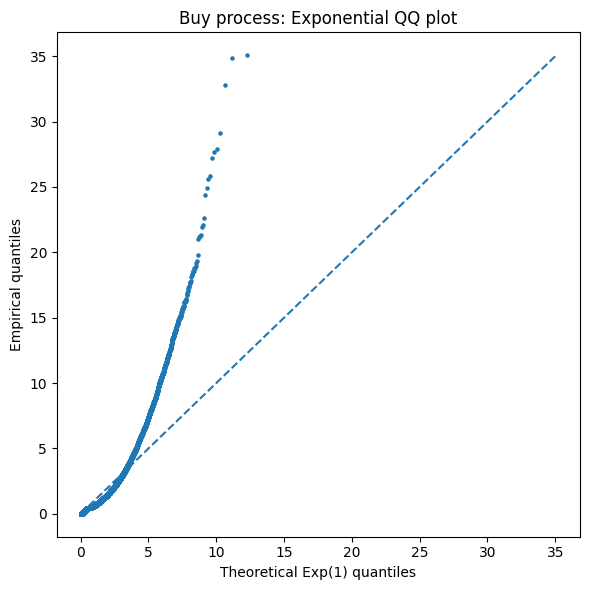

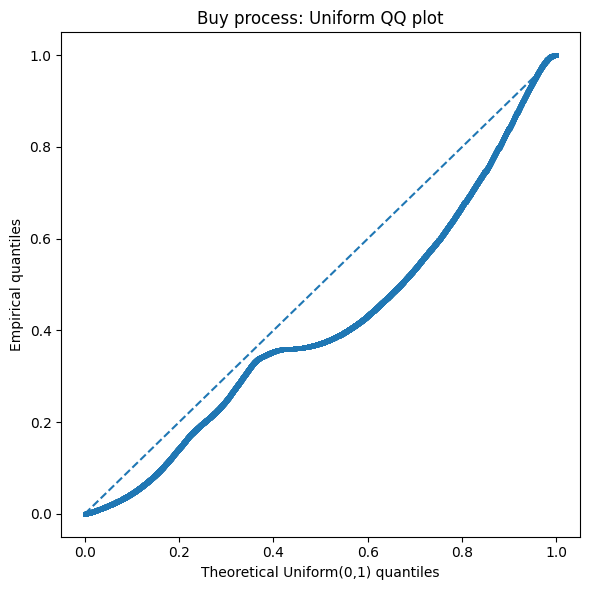

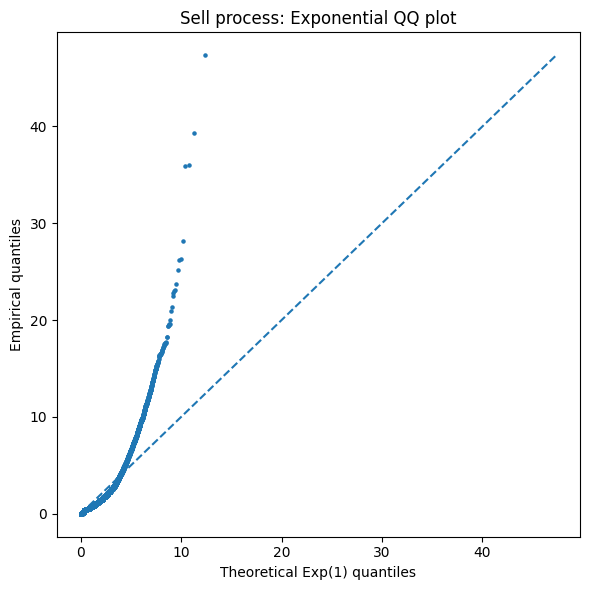

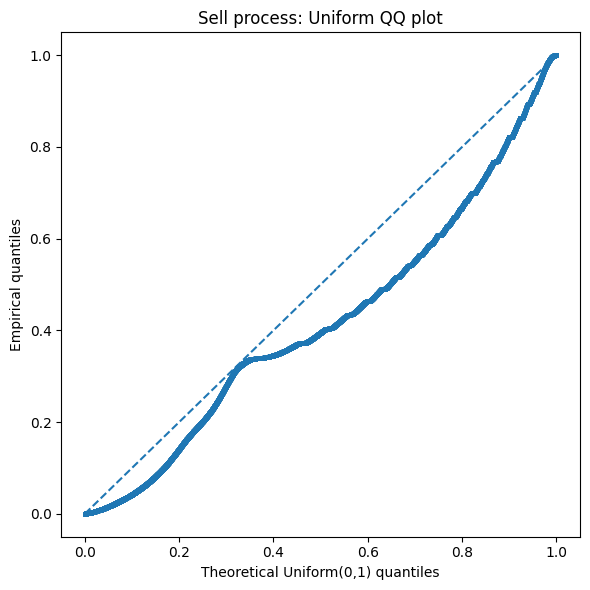

In [56]:
def qq_diagnostics(z, title):
    if torch.is_tensor(z):
        z = z.detach().cpu().numpy()
    else:
        z = np.asarray(z)

    z = z[np.isfinite(z)]
    z = z[z >= 0]

    n = len(z)
    p = (np.arange(1, n + 1) - 0.5) / n
    empirical = np.sort(z)
    theoretical_exp = expon.ppf(p, scale=1)

    plt.figure(figsize=(6, 6))
    plt.scatter(theoretical_exp, empirical, s=5)
    upper = max(theoretical_exp.max(), empirical.max())
    plt.plot([0, upper], [0, upper], linestyle="--")
    plt.xlabel("Theoretical Exp(1) quantiles")
    plt.ylabel("Empirical quantiles")
    plt.title(f"{title}: Exponential QQ plot")
    plt.tight_layout()
    plt.show()
    u = 1 - np.exp(-z)
    empirical_u = np.sort(u)
    theoretical_u = uniform.ppf(p)

    plt.figure(figsize=(6, 6))
    plt.scatter(theoretical_u, empirical_u, s=5)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("Theoretical Uniform(0,1) quantiles")
    plt.ylabel("Empirical quantiles")
    plt.title(f"{title}: Uniform QQ plot")
    plt.tight_layout()
    plt.show()

qq_diagnostics(z_buy_test, "Buy process")
qq_diagnostics(z_sell_test, "Sell process")